# Support Vector Machines (SVM) — From First Principles

This notebook builds a working linear SVM, compares it with scikit-learn, explores the kernel idea, and discusses scaling. The hand-written optimizer is an educational reference implementation, not a replacement for mature solvers.

## 1. Definition and intuition

A support vector machine finds a decision boundary that separates classes while balancing a wide margin against classification errors. The examples closest to the boundary—the **support vectors**—strongly determine its position.

For a linear classifier, the decision score is $f(x)=w^Tx+b$, and the predicted label is the sign of that score. The margin is related to the distance from a point to the hyperplane: $|w^Tx+b|/\|w\|_2$.

## 2. Objective and derivation

For binary labels $y_i\in\{-1,+1\}$, a common soft-margin primal objective is

$$
\min_{w,b}\; \frac12\|w\|_2^2 + C\frac1n\sum_{i=1}^n \max(0, 1-y_i(w^Tx_i+b)).
$$

The first term penalizes large weights and encourages a wide margin. The hinge-loss term penalizes points whose signed score $y_i f(x_i)$ is below 1. A larger $C$ emphasizes training violations more strongly relative to regularization. The hinge loss is convex but not differentiable at its hinge; a subgradient is sufficient for an educational batch optimizer.

For a point with margin below 1, a subgradient contribution to $w$ is $-y_i x_i$ and to $b$ is $-y_i$; for a point with margin at least 1, the hinge term contributes zero. The regularizer contributes $w$.

## 3. Why it works; assumptions and limitations

The linear primal objective is convex, so any global minimizer is a global optimum of this objective (though parameters may not be unique in every formulation). The margin principle can improve generalization, but it is not a guarantee of best accuracy on every dataset. The kernel trick replaces dot products with a kernel-defined similarity, allowing nonlinear boundaries without explicitly constructing every transformed feature.

Important limitations: feature scaling matters; outliers can influence the boundary; `C` needs tuning; kernel SVC may become expensive for large sample counts; class imbalance may require `class_weight`. SVM probabilities are not intrinsic to the basic decision function—probability estimates require an additional calibration procedure.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification, make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import accuracy_score, classification_report

SEED = 42
X, y01 = make_classification(n_samples=700, n_features=8, n_informative=5,
                             n_redundant=1, class_sep=1.45, flip_y=0.025,
                             random_state=SEED)
y = np.where(y01 == 1, 1.0, -1.0)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)
scaler = StandardScaler().fit(X_train)
Xtr = scaler.transform(X_train)
Xte = scaler.transform(X_test)
print('train shape:', Xtr.shape, 'test shape:', Xte.shape)

train shape: (525, 8) test shape: (175, 8)


## 4. Implement a linear SVM from scratch

This uses batch subgradient descent on the primal hinge-loss objective. Inputs are standardized using training data only. The implementation is intentionally simple; production solvers use more sophisticated optimization and convergence checks.

from-scratch test accuracy: 0.8285714285714286


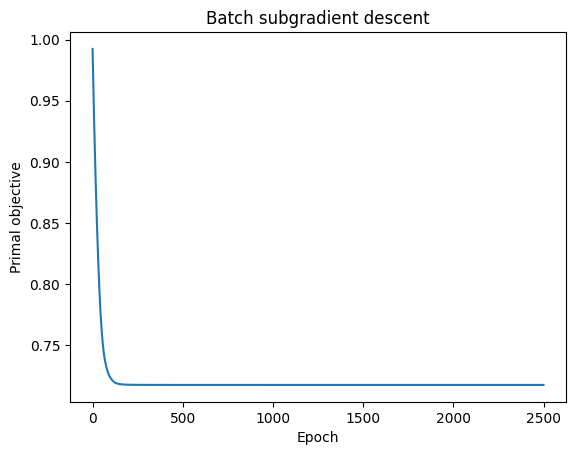

In [2]:
def fit_linear_svm_subgradient(X, y, C=1.0, learning_rate=0.01, epochs=2500):
    """Educational batch subgradient optimizer for binary labels {-1, +1}."""
    X = np.asarray(X, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64)
    if X.ndim != 2 or y.ndim != 1 or len(X) != len(y) or len(X) == 0:
        raise ValueError('X must be 2D and y must be 1D with matching nonzero rows')
    if not np.isin(y, [-1.0, 1.0]).all():
        raise ValueError('y must contain only -1 and +1')
    if C <= 0 or learning_rate <= 0 or epochs < 1:
        raise ValueError('C and learning_rate must be positive; epochs must be >= 1')
    n, d = X.shape
    w = np.zeros(d, dtype=np.float64)
    b = 0.0
    losses = []
    for _ in range(epochs):
        margins = y * (X @ w + b)
        active = margins < 1.0
        # Objective: 0.5 * ||w||^2 + C * mean(hinge loss)
        grad_w = w - C * (X[active].T @ y[active]) / n
        grad_b = -C * y[active].sum() / n
        w -= learning_rate * grad_w
        b -= learning_rate * grad_b
        hinge = np.maximum(0.0, 1.0 - y * (X @ w + b))
        losses.append(0.5 * (w @ w) + C * hinge.mean())
    return w, float(b), losses

w, b, svm_losses = fit_linear_svm_subgradient(Xtr, y_train, C=1.0, learning_rate=0.01, epochs=2500)
pred_scratch = np.where(Xte @ w + b >= 0, 1.0, -1.0)
print('from-scratch test accuracy:', accuracy_score(y_test, pred_scratch))
plt.plot(svm_losses)
plt.xlabel('Epoch'); plt.ylabel('Primal objective'); plt.title('Batch subgradient descent'); plt.show()

## 5. Compare with scikit-learn

`LinearSVC` optimizes a related linear SVM objective. Solver and loss details differ, so the parameters need not match exactly. Compare held-out performance and behavior, not raw parameter equality.

In [3]:
sk_svm = LinearSVC(C=1.0, random_state=SEED, max_iter=10000)
sk_svm.fit(Xtr, y_train)
pred_sklearn = sk_svm.predict(Xte)
print('scikit-learn LinearSVC accuracy:', accuracy_score(y_test, pred_sklearn))
print(classification_report(y_test, pred_sklearn, zero_division=0))
assert accuracy_score(y_test, pred_scratch) > 0.70
assert accuracy_score(y_test, pred_sklearn) > 0.70
assert np.isfinite(w).all() and np.isfinite(b)

scikit-learn LinearSVC accuracy: 0.8457142857142858
              precision    recall  f1-score   support

        -1.0       0.82      0.89      0.85        88
         1.0       0.88      0.80      0.84        87

    accuracy                           0.85       175
   macro avg       0.85      0.85      0.85       175
weighted avg       0.85      0.85      0.85       175



## 6. Kernel idea: a nonlinear boundary

A kernel computes an inner product in an implicit feature space: $K(x,z)=\langle\phi(x),\phi(z)\rangle$. The RBF kernel is $K(x,z)=\exp(-\gamma\|x-z\|^2)$. It can represent nonlinear decision boundaries, but kernel methods can be much more expensive in sample count.

linear SVC accuracy on moons: 0.8938053097345132
RBF SVC accuracy on moons: 1.0


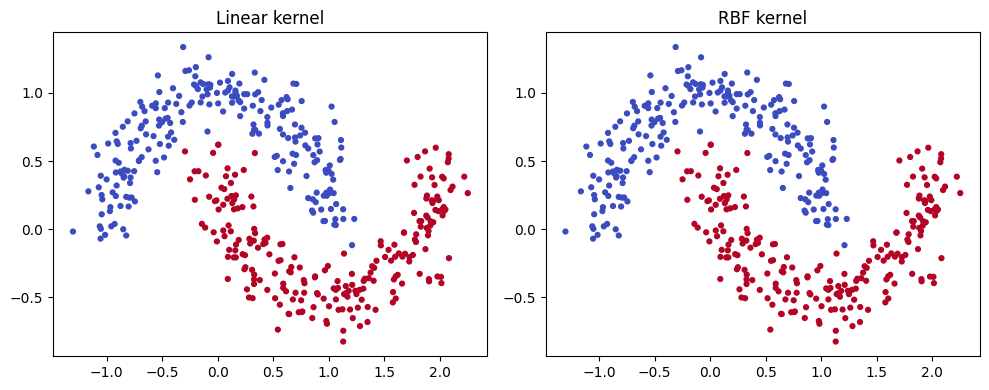

In [4]:
Xm, ym = make_moons(n_samples=450, noise=0.13, random_state=SEED)
Xmu_tr, Xmu_te, ymu_tr, ymu_te = train_test_split(Xm, ym, test_size=0.25,
                                                   random_state=SEED, stratify=ym)
linear_model = make_pipeline(StandardScaler(), SVC(kernel='linear', C=1.0)).fit(Xmu_tr, ymu_tr)
rbf_model = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1.0, gamma='scale')).fit(Xmu_tr, ymu_tr)
print('linear SVC accuracy on moons:', accuracy_score(ymu_te, linear_model.predict(Xmu_te)))
print('RBF SVC accuracy on moons:', accuracy_score(ymu_te, rbf_model.predict(Xmu_te)))
plt.figure(figsize=(10,4))
for i, (model, title) in enumerate([(linear_model, 'Linear kernel'), (rbf_model, 'RBF kernel')], start=1):
    plt.subplot(1, 2, i)
    plt.scatter(Xm[:, 0], Xm[:, 1], c=ym, s=12, cmap='coolwarm')
    plt.title(title)
plt.tight_layout(); plt.show()

## 7. Hyperparameters and best practices

- `C`: larger values punish margin violations more, often reducing training error while increasing sensitivity to noise; smaller values regularize more strongly.
- `kernel`: `linear` for linear boundaries; `rbf` for nonlinear similarity; polynomial kernels are another option.
- `gamma` (RBF): higher values create more local influence and can overfit; lower values create smoother boundaries. `scale` is a useful starting point.
- `class_weight='balanced'`: useful when class frequencies differ meaningfully.
- Scale numeric features inside a pipeline. Tune hyperparameters using cross-validation, not the test set.
- For very large data or sparse high-dimensional features, consider linear methods rather than an exact kernel SVC.

## 8. Training/inference complexity and scaling

Let $n$ be training samples, $d$ features, $m$ query samples, $s$ support vectors, and $T$ optimizer iterations.

| Variant | Training time (rough guide) | Inference time for m samples | Main memory |
|---|---|---|---|
| Linear primal optimizer | This batch implementation: $O(Tnd)$ | $O(md)$ | $O(nd+d)$ for stored dense data and parameters |
| Kernel SVC | Often between $O(n^2)$ and $O(n^3)$, solver/data dependent | Roughly $O(msd)$ for common kernels | Kernel cache can approach $O(n^2)$ |

For millions of examples, start with `LinearSVC` or `SGDClassifier(loss='hinge')`, sparse representations where appropriate, and measured minibatch/online optimization. Kernel approximation (e.g. random Fourier features or Nyström) can trade some exactness for scale.

## 9. GPU suitability: a PyTorch linear hinge-loss model

This demonstrates a linear primal objective on a GPU if CUDA is available. Device transfer overhead makes GPU speedups workload-dependent. The cell falls back to CPU if CUDA is unavailable.

In [5]:
try:
    import torch
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    Xt = torch.tensor(Xtr, dtype=torch.float32, device=device)
    yt = torch.tensor(y_train, dtype=torch.float32, device=device)
    Xvt = torch.tensor(Xte, dtype=torch.float32, device=device)
    w_t = torch.zeros(Xt.shape[1], device=device, requires_grad=True)
    b_t = torch.zeros((), device=device, requires_grad=True)
    optimizer = torch.optim.SGD([w_t, b_t], lr=0.03)
    for _ in range(350):
        optimizer.zero_grad()
        hinge = torch.clamp(1 - yt * (Xt @ w_t + b_t), min=0).mean()
        loss = 0.5 * torch.sum(w_t * w_t) + hinge
        loss.backward()
        optimizer.step()
    with torch.no_grad():
        torch_pred = torch.where(Xvt @ w_t + b_t >= 0, 1.0, -1.0).cpu().numpy()
    print('device:', device, 'PyTorch linear SVM test accuracy:', accuracy_score(y_test, torch_pred))
except ImportError:
    print('PyTorch is not installed; skipping optional GPU demonstration.')

device: cpu PyTorch linear SVM test accuracy: 0.8285714285714286


## 10. Correctness checks and synthesis

The SVM's central trade-off is **margin versus violations**. The linear primal objective is convex; kernel choices expand the kinds of boundaries available at a computational cost. Use a linear SVM for scalable high-dimensional problems, and consider kernel SVC when the dataset is modest and nonlinear structure justifies the cost.

In [6]:
assert len(pred_scratch) == len(y_test)
assert set(np.unique(pred_scratch)).issubset({-1.0, 1.0})
try:
    fit_linear_svm_subgradient(np.ones((3, 2)), np.array([0, 1, 1]))
except ValueError:
    pass
else:
    raise AssertionError('Expected invalid-label check')
print('All SVM notebook checks passed.')

All SVM notebook checks passed.
